In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the merged dataset stored locally in the notebooks folder
final_data = pd.read_csv("final_merged_data.csv")

# Check that it loaded correctly
final_data.shape  

(392, 94)

In [2]:
# Compare how often hunting occurs across the seven rail profiles in percentage
rail_hunting = final_data.groupby("Rail_Profile")["Empty_Truck_Hunted"].mean() * 100

print(rail_hunting)

Rail_Profile
1    78.571429
2    78.571429
3    57.142857
4    75.000000
5    46.428571
6    53.571429
7    60.714286
Name: Empty_Truck_Hunted, dtype: float64


**Looks like rail profiles 1,2 and 4 have substantially higher hunting rates than the other profiles. They are about 15-18% more than the next closest profile at 60%ish (profile 7).**

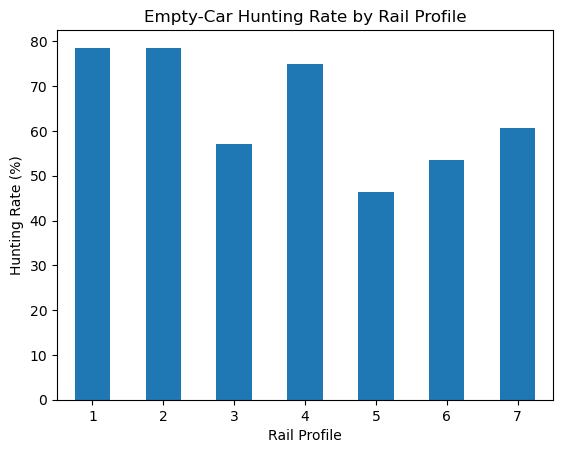

In [3]:
# Visualize differences in hunting frequency across rail profiles
rail_hunting.plot(kind="bar")

plt.xlabel("Rail Profile")
plt.ylabel("Hunting Rate (%)")
plt.title("Empty-Car Hunting Rate by Rail Profile")
plt.xticks(rotation=0)
plt.show()

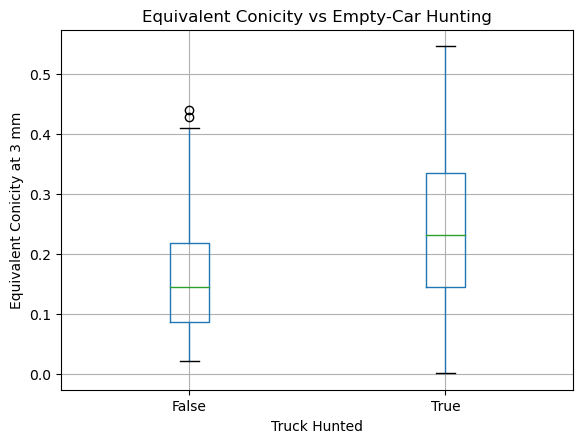

In [4]:
# Compare equivalent conicity between hunting and non-hunting cases
final_data.boxplot(
    column="Eq Con 3mm",
    by="Empty_Truck_Hunted"
)

plt.xlabel("Truck Hunted")
plt.ylabel("Equivalent Conicity at 3 mm")
plt.title("Equivalent Conicity vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**Suggest a higher eq con is associated with empty car hunting since the median is noticeably higher on the true side. The wider range suggest hunting occurs on a broader range of eq con values.**

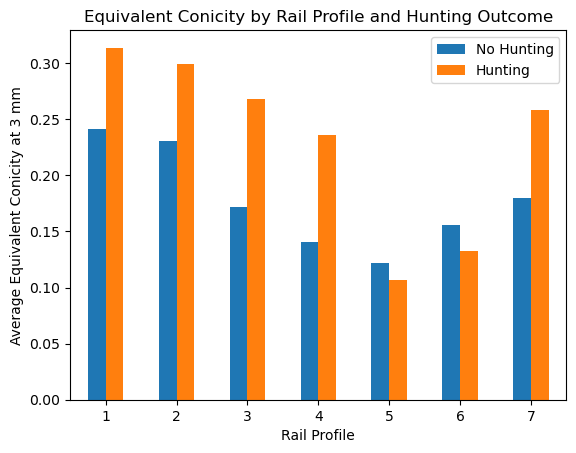

In [5]:
# Compare average equivalent conicity by rail profile and hunting outcome
conicity_by_profile = final_data.groupby(
    ["Rail_Profile", "Empty_Truck_Hunted"]
)["Eq Con 3mm"].mean().unstack()

conicity_by_profile.plot(kind="bar")

plt.xlabel("Rail Profile")
plt.ylabel("Average Equivalent Conicity at 3 mm")
plt.title("Equivalent Conicity by Rail Profile and Hunting Outcome")
plt.xticks(rotation=0)
plt.legend(["No Hunting", "Hunting"])
plt.show()

**Equivalent conicity was generally higher for hunting cases across most rail profiles. Rail profiles 5 and 6 were exceptions, with higher average equivalent conicity among non-hunting cases. These two profiles also had the lowest overall hunting rates. However, the sample sizes within each rail profile and hunting group are relatively small, so these patterns should be treated as exploratory rather than conclusive. The results suggest that the relationship between equivalent conicity and hunting may depend on the rail profile and should be investigated further.**

In [6]:
# Create wheelset hollow wear features from the left and right wheels
final_data["Hollow_Wear_Avg"] = (
    final_data["Max Hollow Wear - AAR_L"] +
    final_data["Max Hollow Wear - AAR_R"]
) / 2

final_data["Hollow_Wear_Diff"] = abs(
    final_data["Max Hollow Wear - AAR_L"] -
    final_data["Max Hollow Wear - AAR_R"]
)

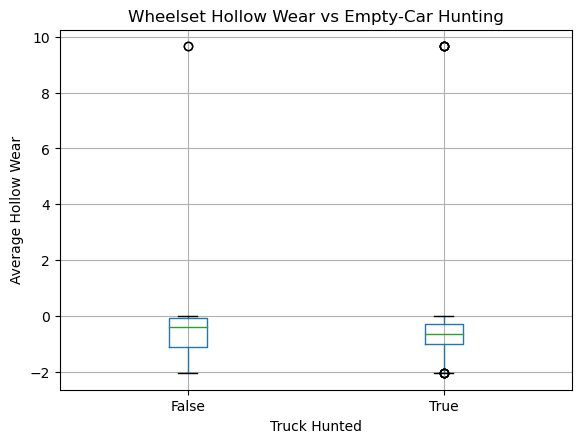

In [7]:
# Compare wheelset hollow wear between hunting and non-hunting cases
final_data.boxplot(
    column="Hollow_Wear_Avg",
    by="Empty_Truck_Hunted"
)

plt.xlabel("Truck Hunted")
plt.ylabel("Average Hollow Wear")
plt.title("Wheelset Hollow Wear vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

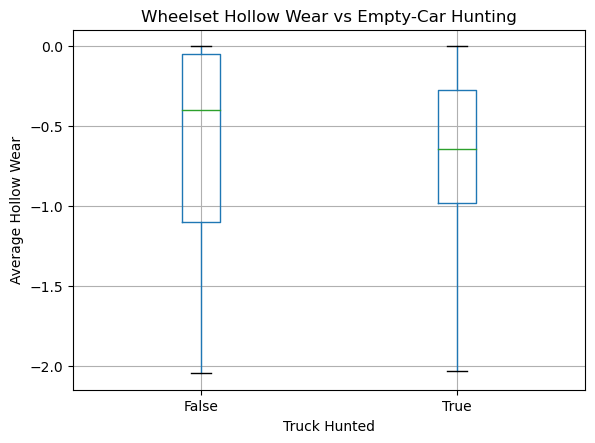

In [8]:
# Compare hollow wear while hiding extreme points so the main distributions are visible
final_data.boxplot(
    column="Hollow_Wear_Avg",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Average Hollow Wear")
plt.title("Wheelset Hollow Wear vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**The hollow wear distributions for hunting and non hunting cases had similar overall ranges. The hunting group had a median farther from zero, while the non hunting group had a wider interquartile range. There was substantial overlap between the two groups, suggesting that this hollow wear measurement alone may not strongly separate hunting from non hunting cases. Figure out if a larger negative value means more hollow wear.**

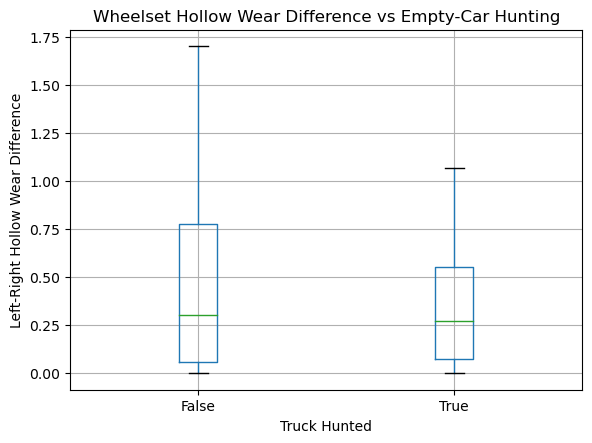

In [9]:
# Check whether uneven hollow wear across the wheelset is related to hunting
final_data.boxplot(
    column="Hollow_Wear_Diff",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Left-Right Hollow Wear Difference")
plt.title("Wheelset Hollow Wear Difference vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**The median left-right hollow wear difference was about the same for hunting and non-hunting cases. The hunting cases were more closely grouped together, while the non-hunting cases had a wider range. Overall, there was a lot of overlap between the two groups, so the left-right hollow wear difference does not seem to have a strong relationship with hunting on its own.**

In [10]:
# Create wheelset qR features from the left and right wheels
final_data["qR_Avg"] = (
    final_data["qR_L"] +
    final_data["qR_R"]
) / 2

final_data["qR_Diff"] = abs(
    final_data["qR_L"] -
    final_data["qR_R"]
)

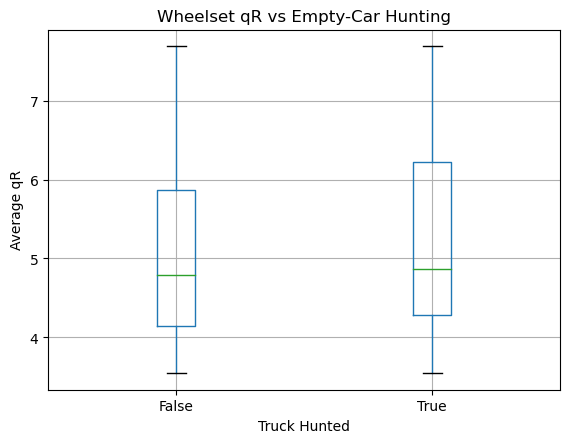

In [11]:
# Compare average wheelset qR between hunting and non-hunting cases
final_data.boxplot(
    column="qR_Avg",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Average qR")
plt.title("Wheelset qR vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**Average qR was very similar between hunting and non-hunting cases. The hunting cases had a slightly higher median and a slightly larger spread in the middle of the data, but both groups had about the same overall range. This suggests that average qR does not have a strong relationship with hunting on its own.**

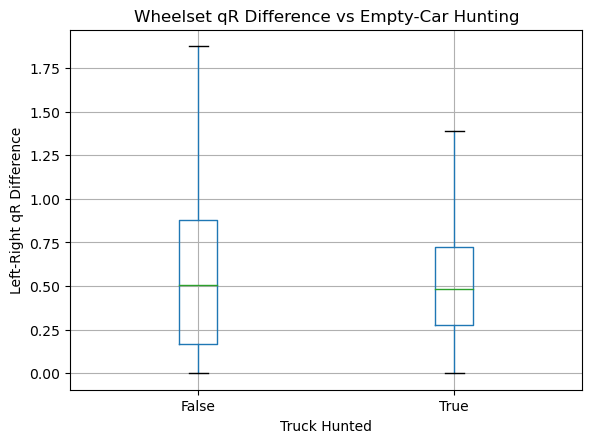

In [12]:
# Check whether left-right qR differences are related to hunting
final_data.boxplot(
    column="qR_Diff",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Left-Right qR Difference")
plt.title("Wheelset qR Difference vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**The median left-right qR difference was about the same for hunting and non-hunting cases. The non-hunting cases had a larger middle spread and a wider overall range. There was a lot of overlap between the groups, so the left-right qR difference does not appear to have a strong relationship with hunting on its own.**

In [13]:
# Create wheelset flange width features from the left and right wheels
final_data["Flange_Width_Avg"] = (
    final_data["Flange Width_L"] +
    final_data["Flange Width_R"]
) / 2

final_data["Flange_Width_Diff"] = abs(
    final_data["Flange Width_L"] -
    final_data["Flange Width_R"]
)

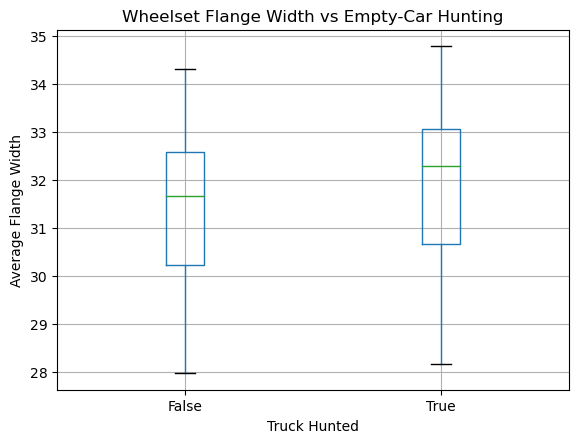

In [14]:
# Compare average flange width between hunting and non-hunting cases
final_data.boxplot(
    column="Flange_Width_Avg",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Average Flange Width")
plt.title("Wheelset Flange Width vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**Average flange width was higher for hunting cases than for non-hunting cases. The two groups had a similar middle spread, but the hunting group was shifted toward higher flange width values overall. This suggests that flange width may have some relationship with hunting and is worth investigating further.**

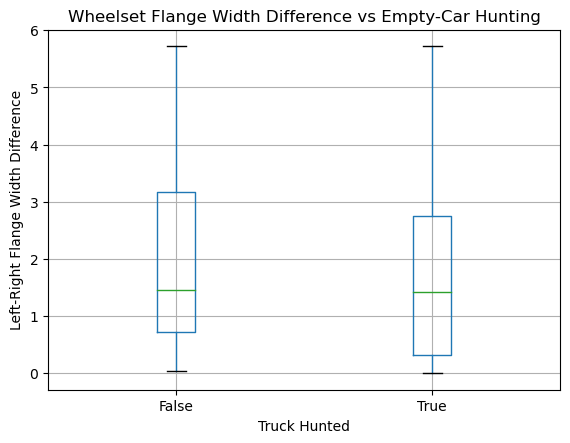

In [15]:
# Check whether left-right flange width differences are related to hunting
final_data.boxplot(
    column="Flange_Width_Diff",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Left-Right Flange Width Difference")
plt.title("Wheelset Flange Width Difference vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**The left-right flange width difference was very similar between hunting and non-hunting cases. The medians and overall ranges were about the same, although the middle of the non-hunting group was slightly higher. Overall, there does not appear to be a strong relationship between left-right flange width difference and hunting.**

In [16]:
# Create wheelset maximum flange angle features
final_data["Flange_Angle_Avg"] = (
    final_data["Max Flange Angle_L"] +
    final_data["Max Flange Angle_R"]
) / 2

final_data["Flange_Angle_Diff"] = abs(
    final_data["Max Flange Angle_L"] -
    final_data["Max Flange Angle_R"]
)

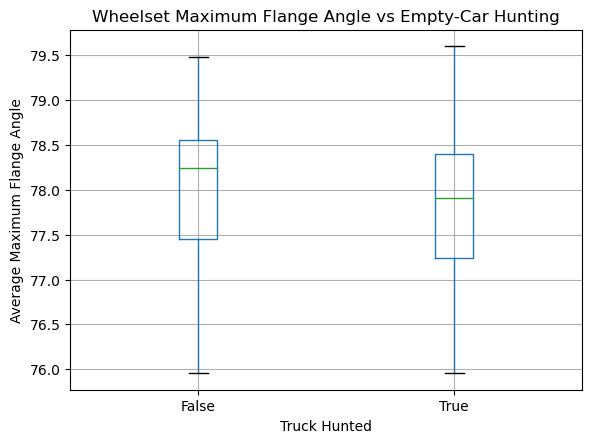

In [17]:
# Compare maximum flange angle between hunting and non-hunting cases
final_data.boxplot(
    column="Flange_Angle_Avg",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Average Maximum Flange Angle")
plt.title("Wheelset Maximum Flange Angle vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**Average maximum flange angle was slightly higher for non-hunting cases. The two groups had similar overall ranges and middle spreads, with the non-hunting group shifted slightly higher. There was still a lot of overlap, so maximum flange angle does not appear to have a strong relationship with hunting on its own.**

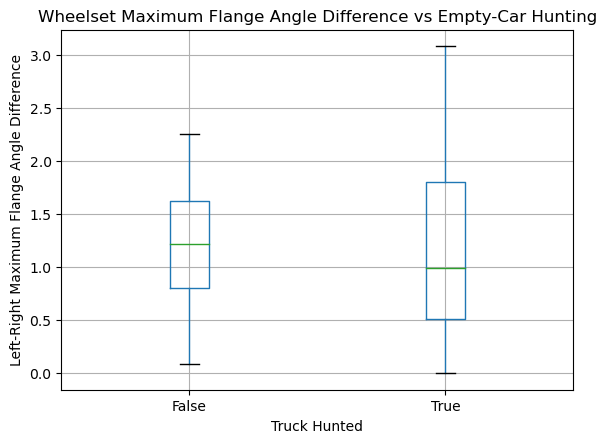

In [18]:
# Check whether left-right maximum flange angle differences are related to hunting
final_data.boxplot(
    column="Flange_Angle_Diff",
    by="Empty_Truck_Hunted",
    showfliers=False
)

plt.xlabel("Truck Hunted")
plt.ylabel("Left-Right Maximum Flange Angle Difference")
plt.title("Wheelset Maximum Flange Angle Difference vs Empty-Car Hunting")
plt.suptitle("")
plt.show()

**The hunting cases had a lower median left-right maximum flange angle difference, but they also had a wider middle spread and a much larger overall range. The non-hunting group was mostly contained within the middle range of the hunting group. This suggests that flange angle difference may be more variable in hunting cases, although it does not clearly separate hunting from non-hunting cases.**

In [19]:
# Create wheelset averages for the main wheel wear measurements
measurements = [
    "Flange Width (Sd)",
    "Flange Height (Sh)",
    "qR",
    "Flange Width",
    "Max Hollow Wear",
    "Flange Radius",
    "Max Flange Angle",
    "Min Flange Root Radius",
    "Max Hollow Wear - AAR"
]

for measurement in measurements:
    final_data[measurement + "_Avg"] = (
        final_data[measurement + "_L"] +
        final_data[measurement + "_R"]
    ) / 2

In [20]:
# Calculate effect size to compare hunting and non-hunting groups
effect_sizes = {}

for measurement in measurements:
    column = measurement + "_Avg"

    hunted = final_data[final_data["Empty_Truck_Hunted"] == True][column].dropna()
    not_hunted = final_data[final_data["Empty_Truck_Hunted"] == False][column].dropna()

    mean_diff = hunted.mean() - not_hunted.mean()

    pooled_std = (
        ((len(hunted) - 1) * hunted.var() +
         (len(not_hunted) - 1) * not_hunted.var()) /
        (len(hunted) + len(not_hunted) - 2)
    ) ** 0.5

    effect_sizes[measurement] = mean_diff / pooled_std

effect_sizes = pd.Series(effect_sizes)
effect_sizes = effect_sizes.reindex(effect_sizes.abs().sort_values(ascending=False).index)

print(effect_sizes)

Flange Width              0.447557
qR                        0.242998
Flange Width (Sd)         0.237174
Flange Radius             0.169241
Min Flange Root Radius    0.166010
Max Hollow Wear          -0.120018
Flange Height (Sh)        0.074917
Max Flange Angle         -0.072482
Max Hollow Wear - AAR    -0.018435
dtype: float64


**Cohen's d measures how different two groups are while also considering how spread out the data is. Here, it compares the average value of each wheel measurement for hunting and non-hunting cases. A positive value means the hunting group had a higher average, while a negative value means the non-hunting group had a higher average. The farther the value is from 0, the larger the difference between the groups. As a general guideline, 0.2 is a small difference, 0.5 is moderate, and 0.8 is large.**

**Average flange width showed a moderate positive difference between hunting and non-hunting cases. qR and flange width (Sd) showed small positive differences. The other wheel measurements showed very little difference. This supports what was seen earlier in the boxplots and helps identify which measurements may be worth looking at further.**

In [21]:
# Check whether the truck result matches the minimum result from its two axles
axle_result = final_data.groupby(
    ["Car", "Truck", "Rail_Profile"]
)["Empty Truck from Acc HS [mph]"].min().reset_index()

truck_result = final_data[
    ["Car", "Truck", "Rail_Profile", "Min Empty Truck from Acc HS [mph]"]
].drop_duplicates()

check = axle_result.merge(
    truck_result,
    on=["Car", "Truck", "Rail_Profile"]
)

matches = (
    check["Empty Truck from Acc HS [mph]"] ==
    check["Min Empty Truck from Acc HS [mph]"]
)

print(matches.value_counts())

True    196
dtype: int64


In [22]:
# Classify empty-car hunting using the truck-level results
final_data["Truck_Hunted"] = (
    final_data["Min Empty Truck from Acc HS [mph]"] < 80
)

# Check whether both axles agree with the truck-level classification
print(
    final_data.groupby(["Car", "Truck", "Rail_Profile"])["Truck_Hunted"]
    .nunique().value_counts()
)

1    196
Name: Truck_Hunted, dtype: int64


In [23]:
# Select physical wheel characteristics and rail profile
features = [
    "Flange_Width_Avg",
    "Flange Width (Sd)_Avg",
    "qR_Avg",
    "Hollow_Wear_Avg",
    "Flange_Angle_Avg",
    "Rail_Profile"
]

X = final_data[features].copy()
y = final_data["Truck_Hunted"].astype(int)

print("Features:", X.columns.tolist())
print("Missing values:", X.isna().sum().sum())
print("Target classes:", sorted(y.unique()))

Features: ['Flange_Width_Avg', 'Flange Width (Sd)_Avg', 'qR_Avg', 'Hollow_Wear_Avg', 'Flange_Angle_Avg', 'Rail_Profile']
Missing values: 0
Target classes: [0, 1]


In [24]:
from sklearn.model_selection import GroupShuffleSplit

# Keep all data from the same car together to avoid data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=final_data["Car"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training classes:", y_train.value_counts().to_dict())
print("Testing classes:", y_test.value_counts().to_dict())

Training rows: 280
Testing rows: 112
Training classes: {1: 178, 0: 102}
Testing classes: {1: 74, 0: 38}


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_features = [
    "Flange_Width_Avg",
    "Flange Width (Sd)_Avg",
    "qR_Avg",
    "Hollow_Wear_Avg",
    "Flange_Angle_Avg"
]

categorical_features = ["Rail_Profile"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Flange_Width_Avg',
                                                   'Flange Width (Sd)_Avg',
                                                   'qR_Avg', 'Hollow_Wear_Avg',
                                                   'Flange_Angle_Avg']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Rail_Profile'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

Accuracy: 0.705

              precision    recall  f1-score   support

  No Hunting       0.69      0.24      0.35        38
     Hunting       0.71      0.95      0.81        74

    accuracy                           0.71       112
   macro avg       0.70      0.59      0.58       112
weighted avg       0.70      0.71      0.65       112



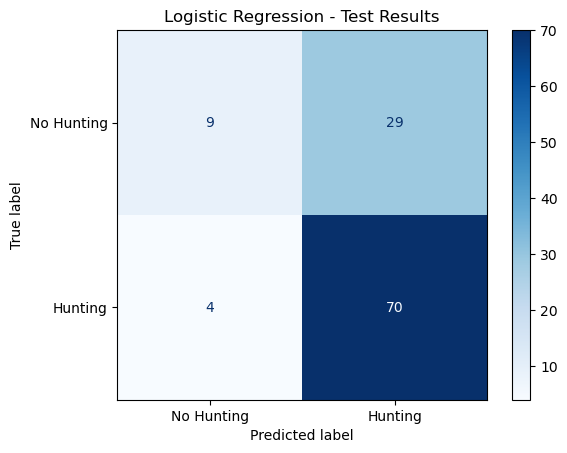

In [26]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict hunting on unseen cars
y_pred = model.predict(X_test)

# Evaluate predictions
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Hunting", "Hunting"],
    zero_division=0
))

# Visualize correct and incorrect predictions
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Hunting", "Hunting"],
    cmap="Blues"
)

plt.title("Logistic Regression - Test Results")
plt.show()

**The model is good at predicting instances where hunting occurred, but not very good at predicting when it did not occur. It is more biased toward predicting hunting simply because there are more examples of hunting in the dataset than not. Need to figure out a solution to deal with that**

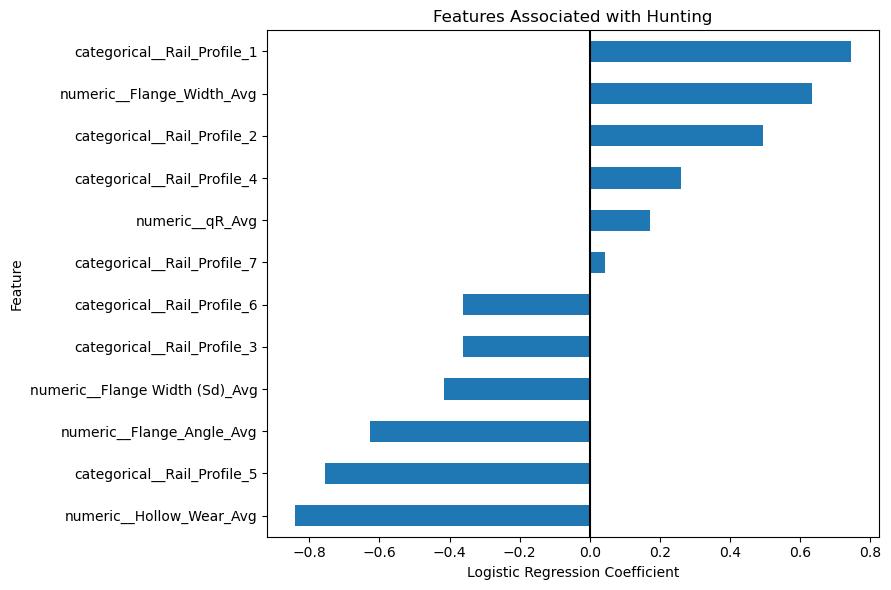

In [27]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

coefficients = model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df = coef_df.sort_values("Coefficient")

coef_df.plot(
    x="Feature",
    y="Coefficient",
    kind="barh",
    legend=False,
    figsize=(9, 6)
)

plt.axvline(0, color="black")
plt.xlabel("Logistic Regression Coefficient")
plt.title("Features Associated with Hunting")
plt.tight_layout()
plt.show()

In [28]:
# Add equivalent conicity to the existing features
X2 = final_data[features + ["Eq Con 3mm"]].copy()

# Use the same train/test split as Model 1
X2_train = X2.iloc[train_idx]
X2_test = X2.iloc[test_idx]

numeric_features_2 = numeric_features + ["Eq Con 3mm"]

preprocessor_2 = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features_2),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

model_2 = Pipeline([
    ("preprocessor", preprocessor_2),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_2.fit(X2_train, y_train)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Flange_Width_Avg',
                                                   'Flange Width (Sd)_Avg',
                                                   'qR_Avg', 'Hollow_Wear_Avg',
                                                   'Flange_Angle_Avg',
                                                   'Eq Con 3mm']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Rail_Profile'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [29]:
from sklearn.metrics import accuracy_score, classification_report

# Predictions from both models
y_pred_1 = model.predict(X_test)
y_pred_2 = model_2.predict(X2_test)

print("MODEL 1 — Without Equivalent Conicity")
print("Accuracy:", round(accuracy_score(y_test, y_pred_1), 3))
print(classification_report(y_test, y_pred_1, zero_division=0))

print("\nMODEL 2 — With Equivalent Conicity")
print("Accuracy:", round(accuracy_score(y_test, y_pred_2), 3))
print(classification_report(y_test, y_pred_2, zero_division=0))

MODEL 1 — Without Equivalent Conicity
Accuracy: 0.705
              precision    recall  f1-score   support

           0       0.69      0.24      0.35        38
           1       0.71      0.95      0.81        74

    accuracy                           0.71       112
   macro avg       0.70      0.59      0.58       112
weighted avg       0.70      0.71      0.65       112


MODEL 2 — With Equivalent Conicity
Accuracy: 0.661
              precision    recall  f1-score   support

           0       0.50      0.26      0.34        38
           1       0.70      0.86      0.77        74

    accuracy                           0.66       112
   macro avg       0.60      0.56      0.56       112
weighted avg       0.63      0.66      0.63       112



**MODEL 1: Left Wheel Only**

In [30]:
wheel_features = [
    "Flange Width",
    "Flange Width (Sd)",
    "Flange Height (Sh)",
    "qR",
    "Max Hollow Wear - AAR",
    "Max Flange Angle",
    "Flange Radius",
    "Min Flange Root Radius"
]

for feature in wheel_features:
    print(feature)
    print("Left:", feature + "_L" in final_data.columns)
    print("Right:", feature + "_R" in final_data.columns)
    print()

Flange Width
Left: True
Right: True

Flange Width (Sd)
Left: True
Right: True

Flange Height (Sh)
Left: True
Right: True

qR
Left: True
Right: True

Max Hollow Wear - AAR
Left: True
Right: True

Max Flange Angle
Left: True
Right: True

Flange Radius
Left: True
Right: True

Min Flange Root Radius
Left: True
Right: True



In [31]:
# Select the left wheel measurements
left_features = [feature + "_L" for feature in wheel_features]

# Set up the features and hunting outcome
X_left = final_data[left_features].copy()
y = final_data["Truck_Hunted"].astype(int)

# Check the data before modeling
print("X shape:", X_left.shape)
print("Missing values:", X_left.isna().sum().sum())
print("Hunting outcomes:")
print(y.value_counts())

X shape: (392, 8)
Missing values: 0
Hunting outcomes:
1    252
0    140
Name: Truck_Hunted, dtype: int64


In [32]:


# Split by car so the same car isn't in both sets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_left, y, groups=final_data["Car"])
)

# Create the training and testing sets
X_left_train = X_left.iloc[train_idx]
X_left_test = X_left.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Check the sizes of each set
print("Training observations:", len(X_left_train))
print("Testing observations:", len(X_left_test))
print("Training hunting outcomes:")
print(y_train.value_counts())
print("Testing hunting outcomes:")
print(y_test.value_counts())

Training observations: 280
Testing observations: 112
Training hunting outcomes:
1    178
0    102
Name: Truck_Hunted, dtype: int64
Testing hunting outcomes:
1    74
0    38
Name: Truck_Hunted, dtype: int64


In [33]:
# Scale the wheel measurements and build the model
left_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model using the left wheel data
left_model.fit(X_left_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [34]:
from sklearn.metrics import confusion_matrix
# Predict hunting on the testing data
y_pred_left = left_model.predict(X_left_test)

# Calculate accuracy and display performance metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_left), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_left))

# Show the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_left))

Accuracy: 0.67

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.11      0.18        38
           1       0.68      0.96      0.79        74

    accuracy                           0.67       112
   macro avg       0.62      0.53      0.49       112
weighted avg       0.64      0.67      0.58       112

Confusion Matrix:
[[ 4 34]
 [ 3 71]]


**MODEL 2: RIGHT WHEEL ONLY**

In [35]:
# Select the right wheel measurements
right_features = [feature + "_R" for feature in wheel_features]
X_right = final_data[right_features].copy()

# Use the same training and testing observations
X_right_train = X_right.iloc[train_idx]
X_right_test = X_right.iloc[test_idx]

# Build and train the right wheel model
right_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

right_model.fit(X_right_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [36]:
# Predict hunting using the right wheel measurements
y_pred_right = right_model.predict(X_right_test)

# Display accuracy and classification metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_right), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_right))

# Show the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_right))

Accuracy: 0.634

Classification Report:
              precision    recall  f1-score   support

           0       0.43      0.24      0.31        38
           1       0.68      0.84      0.75        74

    accuracy                           0.63       112
   macro avg       0.55      0.54      0.53       112
weighted avg       0.60      0.63      0.60       112

Confusion Matrix:
[[ 9 29]
 [12 62]]


**MODEL 3: LEFT/RIGHT WEAR DIFFERENCE**

In [37]:
# Calculate differences between left and right wheel measurements
difference_features = []

for feature in wheel_features:
    column_name = feature + "_Diff"

    final_data[column_name] = abs(
        final_data[feature + "_L"] - final_data[feature + "_R"]
    )

    difference_features.append(column_name)

# Set up the difference-only dataset
X_diff = final_data[difference_features].copy()

# Check the features and missing values
print("Features:", difference_features)
print("X shape:", X_diff.shape)
print("Missing values:", X_diff.isna().sum().sum())

Features: ['Flange Width_Diff', 'Flange Width (Sd)_Diff', 'Flange Height (Sh)_Diff', 'qR_Diff', 'Max Hollow Wear - AAR_Diff', 'Max Flange Angle_Diff', 'Flange Radius_Diff', 'Min Flange Root Radius_Diff']
X shape: (392, 8)
Missing values: 0


In [38]:
# Use the same training and testing split as the previous models
X_diff_train = X_diff.iloc[train_idx]
X_diff_test = X_diff.iloc[test_idx]

# Build the logistic regression model using wheel differences
diff_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
diff_model.fit(X_diff_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [39]:
# Predict hunting using left/right wheel differences
y_pred_diff = diff_model.predict(X_diff_test)

# Display accuracy and classification metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_diff), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_diff))

# Show the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_diff))

Accuracy: 0.652

Classification Report:
              precision    recall  f1-score   support

           0       0.43      0.08      0.13        38
           1       0.67      0.95      0.78        74

    accuracy                           0.65       112
   macro avg       0.55      0.51      0.46       112
weighted avg       0.59      0.65      0.56       112

Confusion Matrix:
[[ 3 35]
 [ 4 70]]


**MODEL 4: BOTH WHEELS COMBINED**

In [40]:
# Combine left and right wheel measurements
combined_features = left_features + right_features

X_combined = final_data[combined_features].copy()

# Use the same training and testing split
X_combined_train = X_combined.iloc[train_idx]
X_combined_test = X_combined.iloc[test_idx]

# Check the combined dataset
print("X shape:", X_combined.shape)
print("Missing values:", X_combined.isna().sum().sum())

X shape: (392, 16)
Missing values: 0


In [41]:
# Build the logistic regression model using both wheels
combined_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model using both left and right wheel measurements
combined_model.fit(X_combined_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [42]:
# Predict hunting using both wheels
y_pred_combined = combined_model.predict(X_combined_test)

# Display accuracy and classification metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_combined), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_combined))

# Show the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_combined))

Accuracy: 0.607

Classification Report:
              precision    recall  f1-score   support

           0       0.29      0.11      0.15        38
           1       0.65      0.86      0.74        74

    accuracy                           0.61       112
   macro avg       0.47      0.49      0.45       112
weighted avg       0.53      0.61      0.54       112

Confusion Matrix:
[[ 4 34]
 [10 64]]


**MODEL 5: WHEEL AVERAGES + DIFFERENCES**

In [43]:
# Calculate average measurements across both wheels
average_features = []

for feature in wheel_features:
    column_name = feature + "_Avg"

    final_data[column_name] = (
        final_data[feature + "_L"] + final_data[feature + "_R"]
    ) / 2

    average_features.append(column_name)

# Combine wheel averages and left/right differences
avg_diff_features = average_features + difference_features

X_avg_diff = final_data[avg_diff_features].copy()

# Use the same training and testing observations
X_avg_diff_train = X_avg_diff.iloc[train_idx]
X_avg_diff_test = X_avg_diff.iloc[test_idx]

# Check the dataset
print("X shape:", X_avg_diff.shape)
print("Missing values:", X_avg_diff.isna().sum().sum())

X shape: (392, 16)
Missing values: 0


In [44]:
# Build the logistic regression model using averages and differences
avg_diff_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
avg_diff_model.fit(X_avg_diff_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [45]:
# Predict hunting using wheel averages and differences
y_pred_avg_diff = avg_diff_model.predict(X_avg_diff_test)

# Display accuracy and classification metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_avg_diff), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_avg_diff))

# Show the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_avg_diff))

Accuracy: 0.589

Classification Report:
              precision    recall  f1-score   support

           0       0.21      0.08      0.12        38
           1       0.64      0.85      0.73        74

    accuracy                           0.59       112
   macro avg       0.43      0.47      0.42       112
weighted avg       0.50      0.59      0.52       112

Confusion Matrix:
[[ 3 35]
 [11 63]]


**BALANCED AVERAGES + DIFFERENCES MODEL**

In [46]:
# Build logistic regression with balanced class weights
balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train using wheel averages and differences
balanced_model.fit(X_avg_diff_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [47]:
from sklearn.metrics import balanced_accuracy_score

# Predict hunting using balanced logistic regression
y_pred_balanced = balanced_model.predict(X_avg_diff_test)

# Display model performance
print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred_balanced), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

# Show the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

Accuracy: 0.634
Balanced Accuracy: 0.582

Classification Report:
              precision    recall  f1-score   support

           0       0.46      0.42      0.44        38
           1       0.71      0.74      0.73        74

    accuracy                           0.63       112
   macro avg       0.59      0.58      0.58       112
weighted avg       0.63      0.63      0.63       112

Confusion Matrix:
[[16 22]
 [19 55]]


**BALANCED LEFT WHEEL**

In [48]:
# Build balanced logistic regression using left wheel measurements
balanced_left_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train using left wheel measurements
balanced_left_model.fit(X_left_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [49]:
# Predict hunting using the balanced left wheel model
y_pred_balanced_left = balanced_left_model.predict(X_left_test)

# Display accuracy and classification metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced_left), 3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred_balanced_left), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced_left))

# Show the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced_left))

Accuracy: 0.527
Balanced Accuracy: 0.507

Classification Report:
              precision    recall  f1-score   support

           0       0.35      0.45      0.39        38
           1       0.67      0.57      0.61        74

    accuracy                           0.53       112
   macro avg       0.51      0.51      0.50       112
weighted avg       0.56      0.53      0.54       112

Confusion Matrix:
[[17 21]
 [32 42]]


**FEATURE IMPORTANCE OF AVERAGES AND DIFFERENCES MODEL**

In [50]:
# Extract coefficients from the balanced logistic regression model
coefficients = balanced_model.named_steps["classifier"].coef_[0]

# Create a table of wheel features and their coefficients
feature_importance = pd.DataFrame({
    "Feature": avg_diff_features,
    "Coefficient": coefficients,
    "Absolute Coefficient": abs(coefficients)
})

# Sort by coefficient magnitude
feature_importance = feature_importance.sort_values(
    "Absolute Coefficient", ascending=False
)

print(feature_importance.to_string(index=False))

                    Feature  Coefficient  Absolute Coefficient
    Flange Height (Sh)_Diff     2.598447              2.598447
Min Flange Root Radius_Diff    -0.967286              0.967286
  Max Hollow Wear - AAR_Avg    -0.946235              0.946235
           Flange Width_Avg     0.623886              0.623886
 Max Hollow Wear - AAR_Diff    -0.414109              0.414109
                     qR_Avg     0.379821              0.379821
     Flange Width (Sd)_Diff    -0.348772              0.348772
                    qR_Diff    -0.335697              0.335697
      Flange Width (Sd)_Avg    -0.331892              0.331892
          Flange Width_Diff    -0.312649              0.312649
      Max Flange Angle_Diff     0.241785              0.241785
     Flange Height (Sh)_Avg     0.163558              0.163558
 Min Flange Root Radius_Avg     0.149149              0.149149
       Max Flange Angle_Avg    -0.082002              0.082002
         Flange Radius_Diff     0.037028              0

What we looked at:
We examined the standardized coefficients from a balanced logistic regression model using 16 physical wheel characteristics: eight average measurements and eight left/right differences. The goal was to identify which characteristics were most strongly associated with rail vehicle hunting.
What we found:
- Flange Height Difference (+2.60): The strongest predictor by coefficient magnitude. Greater differences between left and right flange heights were associated with increased predicted hunting probability.
- Minimum Flange Root Radius Difference (-0.97): Larger differences were associated with decreased predicted hunting probability.
- Average Hollow Wear (-0.95): Showed a relatively strong negative association with hunting, although the measurement's sign convention needs clarification.
- Average Flange Width (+0.62): Larger average flange widths were associated with increased predicted hunting probability, consistent with our earlier EDA findings.
- Other Measurements: Most remaining characteristics had smaller coefficients, suggesting weaker contributions within this particular model.


Overall Findings:
Both average wheel characteristics and left/right differences appear relevant to hunting predictions. Flange height asymmetry was particularly prominent, while average flange width showed consistency with earlier exploratory findings.
However, the model achieved only 63.4% accuracy and 58.2% balanced accuracy, so these results should be considered preliminary associations rather than confirmed physical causes of hunting. Further validation is needed to determine which characteristics are consistently informative.

In [51]:
# Select the six strongest features from our model
top_features = feature_importance["Feature"].head(6).tolist()

# Check whether these measurements are correlated
correlations = X_avg_diff_train[top_features].corr()

print(correlations.round(2).to_string())

                             Flange Height (Sh)_Diff  Min Flange Root Radius_Diff  Max Hollow Wear - AAR_Avg  Flange Width_Avg  Max Hollow Wear - AAR_Diff  qR_Avg
Flange Height (Sh)_Diff                         1.00                         0.82                       0.91             -0.21                        0.98   -0.19
Min Flange Root Radius_Diff                     0.82                         1.00                       0.72              0.08                        0.80    0.12
Max Hollow Wear - AAR_Avg                       0.91                         0.72                       1.00             -0.21                        0.88   -0.17
Flange Width_Avg                               -0.21                         0.08                      -0.21              1.00                       -0.19    0.36
Max Hollow Wear - AAR_Diff                      0.98                         0.80                       0.88             -0.19                        1.00   -0.17
qR_Avg                

- **Flange height difference** is highly correlated with hollow wear difference (0.98), average hollow wear (0.91), and flange root radius difference (0.82).
- These strong correlations suggest that several features capture overlapping information about wheel wear.
- **Average flange width** has relatively weak correlations with these features, suggesting it may provide more independent predictive information.
- **Overall:** Flange geometry and uneven wheel wear appear relevant to hunting, but the strong correlations make it difficult to determine which individual measurements are most important.

**Grouped cross-validation to see whether the flange-related findings hold across different cars**

In [52]:
from sklearn.model_selection import GroupKFold, cross_validate

# Keep all observations from the same car together
cv = GroupKFold(n_splits=5)

# Evaluate balanced logistic regression across five folds
cv_results = cross_validate(
    balanced_model,
    X_avg_diff,
    y,
    groups=final_data["Car"],
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "f1_macro": "f1_macro"
    }
)

# Display average performance across folds
for metric in ["accuracy", "balanced_accuracy", "f1_macro"]:
    scores = cv_results["test_" + metric]
    print(f"{metric}: {scores.mean():.3f} (+/- {scores.std():.3f})")

accuracy: 0.514 (+/- 0.145)
balanced_accuracy: 0.552 (+/- 0.081)
f1_macro: 0.494 (+/- 0.128)


**Tuning L2 regularization in balanced logistic regression using grouped cross-validation to reduce the effects of correlated wheel measurements and improve hunting prediction performance.**

In [53]:
from sklearn.model_selection import GridSearchCV

# Build balanced logistic regression with L2 regularization
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        penalty="l2"
    ))
])

# Test different regularization strengths
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

# Tune using grouped cross-validation
ridge_search = GridSearchCV(
    ridge_model,
    param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="balanced_accuracy"
)

ridge_search.fit(
    X_avg_diff,
    y,
    groups=final_data["Car"]
)

print("Best C:", ridge_search.best_params_["classifier__C"])
print("Best CV Balanced Accuracy:", round(ridge_search.best_score_, 3))

Best C: 100
Best CV Balanced Accuracy: 0.572


**Step 1: Train and tune XGBoost**

In [54]:
from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV

#Build an XGBoost model using all wheel averages and differences
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

#Test a small range of model settings
param_grid = {
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [100, 200],
    "min_child_weight": [3, 8]
}

#Tune the model while keeping observations from the same car together
xgb_search = GridSearchCV(
    xgb_model,
    param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="balanced_accuracy",
    n_jobs=-1
)

xgb_search.fit(
    X_avg_diff_train,
    y_train,
    groups=final_data["Car"].iloc[train_idx]
)

print("Best parameters:", xgb_search.best_params_)
print("Best training CV balanced accuracy:", round(xgb_search.best_score_, 3))

Best parameters: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 8, 'n_estimators': 100}
Best training CV balanced accuracy: 0.539


In [55]:
# Use the best XGBoost model from cross validation
best_xgb = xgb_search.best_estimator_

# Predict hunting on the held out test cars
y_pred_xgb = best_xgb.predict(X_avg_diff_test)

# Display model performance
print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred_xgb), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy: 0.679
Balanced Accuracy: 0.61

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.39      0.45        38
           1       0.73      0.82      0.77        74

    accuracy                           0.68       112
   macro avg       0.63      0.61      0.61       112
weighted avg       0.66      0.68      0.66       112

Confusion Matrix:
[[15 23]
 [13 61]]


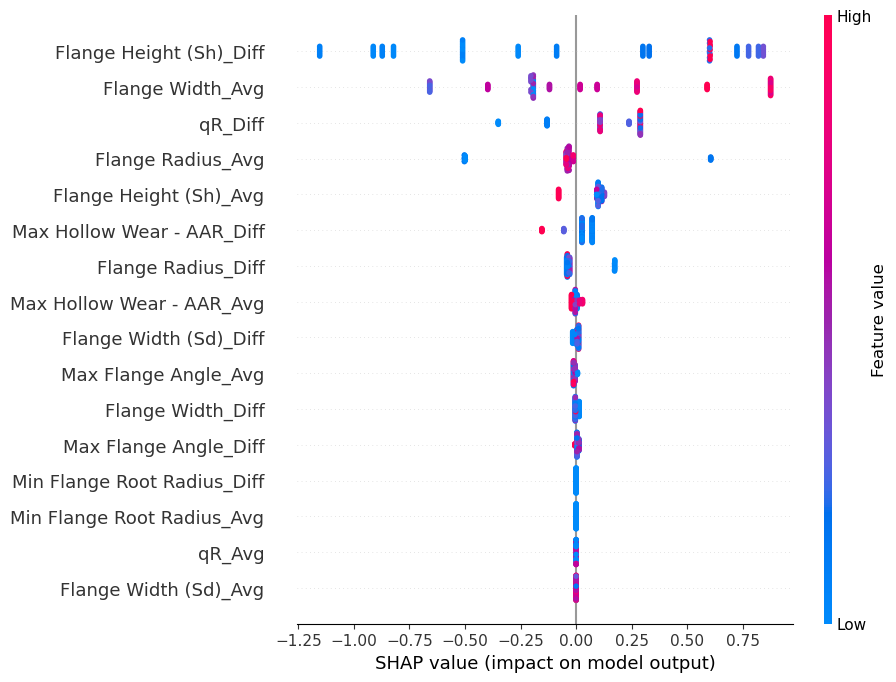

In [56]:
import shap
import matplotlib.pyplot as plt

#Explain predictions on the held out test cars
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_avg_diff_test)

#Show which measurements push predictions toward or away from hunting
shap.plots.beeswarm(shap_values, max_display=16)
plt.show()

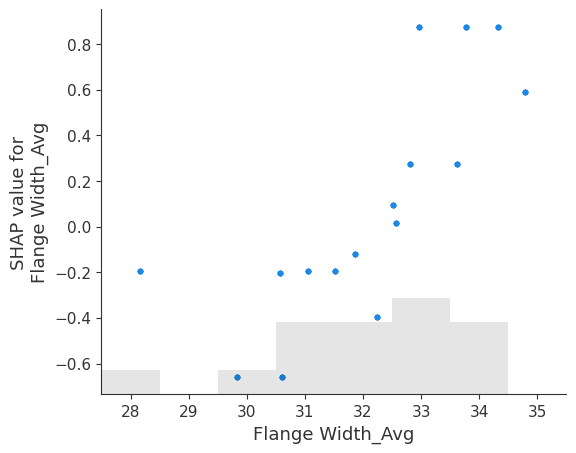

In [57]:
#Look at how average flange width affects hunting predictions
shap.plots.scatter(
    shap_values[:, "Flange Width_Avg"]
)

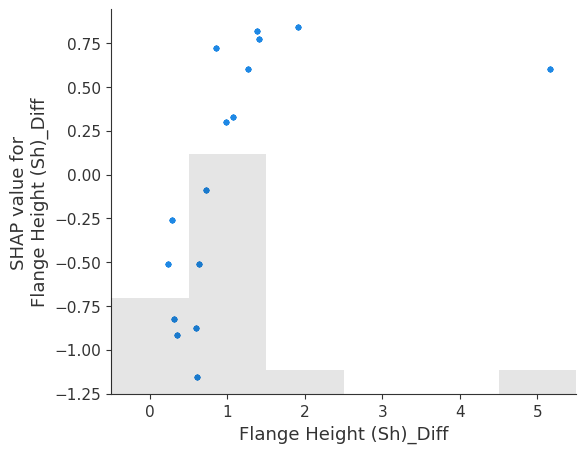

In [58]:
#Look at how left/right flange height differences affect predictions
shap.plots.scatter(
    shap_values[:, "Flange Height (Sh)_Diff"]
)

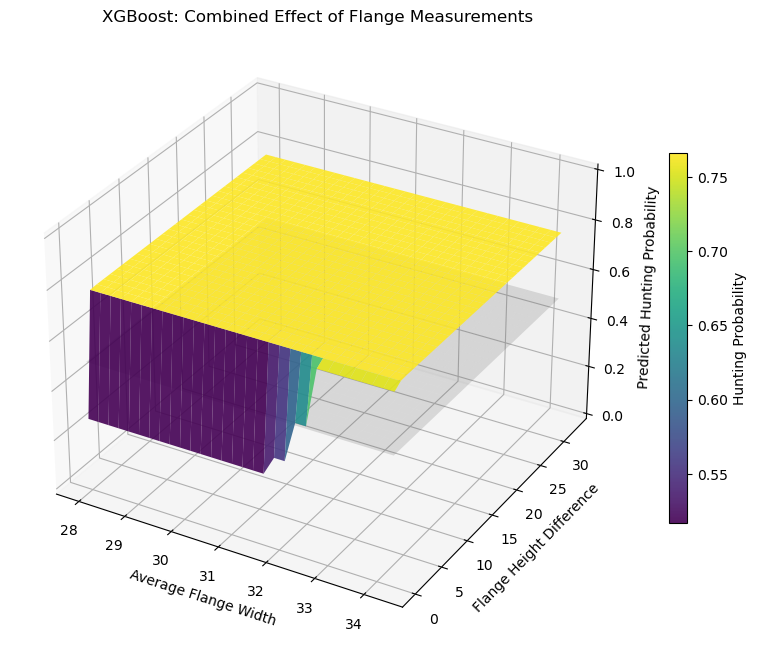

In [59]:
# Two flange measurements to investigate
width_col = "Flange Width_Avg"
height_col = "Flange Height (Sh)_Diff"

# Create a grid within the observed measurement ranges
width_vals = np.linspace(
    X_avg_diff_train[width_col].min(),
    X_avg_diff_train[width_col].max(), 30
)
height_vals = np.linspace(
    X_avg_diff_train[height_col].min(),
    X_avg_diff_train[height_col].max(), 30
)

W, H = np.meshgrid(width_vals, height_vals)
Z = np.zeros_like(W)

# Average model predictions across the training observations
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        X_temp = X_avg_diff_train.copy()
        X_temp[width_col] = W[i, j]
        X_temp[height_col] = H[i, j]

        Z[i, j] = best_xgb.predict_proba(X_temp)[:, 1].mean()

# Plot the 3D hunting probability surface
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(W, H, Z, cmap="viridis", alpha=0.9)

# Add the 50% hunting probability reference plane
ax.plot_surface(
    W, H, np.full_like(Z, 0.5),
    color="gray", alpha=0.2
)

ax.set_xlabel("Average Flange Width")
ax.set_ylabel("Flange Height Difference")
ax.set_zlabel("Predicted Hunting Probability")
ax.set_zlim(0, 1)
ax.set_title("XGBoost: Combined Effect of Flange Measurements")

fig.colorbar(surface, ax=ax, shrink=0.6, label="Hunting Probability")

plt.show()

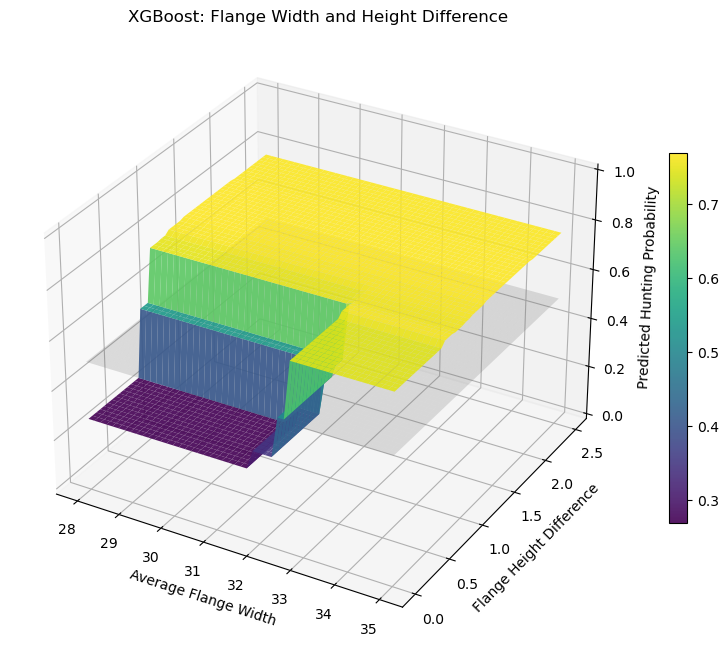

In [61]:
# Focus on the main observed measurement ranges
width_vals = np.linspace(28, 35, 50)
height_vals = np.linspace(0, 2.5, 50)

W, H = np.meshgrid(width_vals, height_vals)
Z = np.zeros_like(W)

for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        X_temp = X_avg_diff_train.copy()
        X_temp["Flange Width_Avg"] = W[i, j]
        X_temp["Flange Height (Sh)_Diff"] = H[i, j]

        Z[i, j] = best_xgb.predict_proba(X_temp)[:, 1].mean()

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(W, H, Z, cmap="viridis", alpha=0.9)

ax.plot_surface(
    W, H, np.full_like(Z, 0.5),
    color="gray", alpha=0.2
)

ax.set_xlabel("Average Flange Width")
ax.set_ylabel("Flange Height Difference")
ax.set_zlabel("Predicted Hunting Probability")
ax.set_zlim(0, 1)
ax.set_title("XGBoost: Flange Width and Height Difference")

fig.colorbar(surface, ax=ax, shrink=0.6)

plt.show()

In [62]:
# Find the combination with the highest predicted hunting probability
max_idx = np.unravel_index(np.argmax(Z), Z.shape)

best_width = W[max_idx]
best_height = H[max_idx]
max_prob = Z[max_idx]

print(f"Average Flange Width: {best_width:.3f}")
print(f"Flange Height Difference: {best_height:.3f}")
print(f"Highest Predicted Hunting Probability: {max_prob:.2%}")

Average Flange Width: 28.000
Flange Height Difference: 1.327
Highest Predicted Hunting Probability: 76.94%


In [63]:
# Find combinations within 0.5 percentage points of the maximum
high_risk = Z >= Z.max() - 0.005

print("Highest predicted probability:", round(Z.max() * 100, 2), "%")

print("Flange Width Range:",
      round(W[high_risk].min(), 3),
      "to",
      round(W[high_risk].max(), 3))

print("Flange Height Difference Range:",
      round(H[high_risk].min(), 3),
      "to",
      round(H[high_risk].max(), 3))

Highest predicted probability: 76.94 %
Flange Width Range: 28.0 to 35.0
Flange Height Difference Range: 1.327 to 2.5


In [64]:
# Compare observed hunting rates above and below the model threshold
threshold = 1.327

comparison = final_data.copy()

comparison["Height Group"] = np.where(
    comparison["Flange Height (Sh)_Diff"] >= threshold,
    "High Difference",
    "Low Difference"
)

results = comparison.groupby("Height Group")["Truck_Hunted"].agg(
    Count="count",
    Hunting_Rate="mean"
)

results["Hunting_Rate"] *= 100

print(results.round(2))

                 Count  Hunting_Rate
Height Group                        
High Difference    119         75.63
Low Difference     273         59.34


In [65]:
# Compare observed hunting rates for both flange measurements
comparison = final_data.copy()

comparison["Width Group"] = np.where(
    comparison["Flange Width_Avg"] >= 32.5,
    "High Width", "Low Width"
)

comparison["Height Group"] = np.where(
    comparison["Flange Height (Sh)_Diff"] >= 1.327,
    "High Difference", "Low Difference"
)

results = comparison.groupby(
    ["Width Group", "Height Group"]
)["Truck_Hunted"].agg(
    Count="count",
    Hunting_Rate="mean"
)

results["Hunting_Rate"] *= 100

print(results.round(2))

                             Count  Hunting_Rate
Width Group Height Group                        
High Width  High Difference     35         82.86
            Low Difference     133         69.17
Low Width   High Difference     84         72.62
            Low Difference     140         50.00


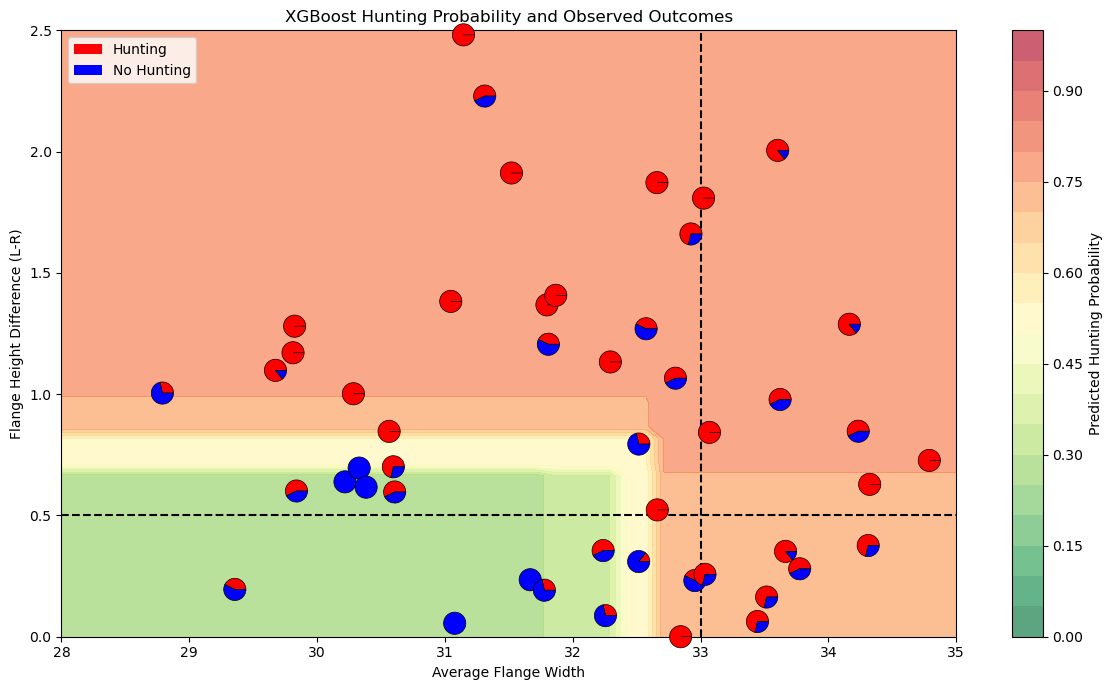

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.offsetbox import AnnotationBbox, DrawingArea
from matplotlib.patches import Wedge

fig, ax = plt.subplots(figsize=(12, 7))

# XGBoost predicted hunting probability
contour = ax.contourf(
    W, H, Z,
    levels=np.linspace(0, 1, 21),
    cmap="RdYlGn_r",
    alpha=0.65
)

plt.colorbar(contour, ax=ax, label="Predicted Hunting Probability")

# Group actual observations by measurement combination
counts = final_data.groupby(
    ["Flange Width_Avg", "Flange Height (Sh)_Diff"]
)["Truck_Hunted"].agg(
    Total="count",
    Hunted="sum"
).reset_index()

counts = counts[
    counts["Flange Width_Avg"].between(28, 35) &
    counts["Flange Height (Sh)_Diff"].between(0, 2.5)
]

# Draw circular pie charts with fixed display size
for _, row in counts.iterrows():
    x = row["Flange Width_Avg"]
    y = row["Flange Height (Sh)_Diff"]
    fraction = row["Hunted"] / row["Total"]

    size = 16
    radius = size / 2

    drawing = DrawingArea(size, size, 0, 0)

    # Hunting portion (red)
    drawing.add_artist(Wedge(
        (radius, radius), radius,
        0, 360 * fraction,
        facecolor="red",
        edgecolor="black",
        linewidth=0.5
    ))

    # Non-hunting portion (blue)
    drawing.add_artist(Wedge(
        (radius, radius), radius,
        360 * fraction, 360,
        facecolor="blue",
        edgecolor="black",
        linewidth=0.5
    ))

    ax.add_artist(AnnotationBbox(
        drawing, (x, y),
        frameon=False,
        pad=0,
        zorder=5
    ))

# Candidate thresholds
ax.axvline(33.0, color="black", linestyle="--", linewidth=1.5)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1.5)

ax.set_xlim(28, 35)
ax.set_ylim(0, 2.5)

ax.set_aspect("auto")

ax.set_xlabel("Average Flange Width")
ax.set_ylabel("Flange Height Difference (L-R)")
ax.set_title("XGBoost Hunting Probability and Observed Outcomes")

ax.legend(handles=[
    Patch(facecolor="red", label="Hunting"),
    Patch(facecolor="blue", label="No Hunting")
], loc="upper left")

plt.tight_layout()
plt.show()

In [69]:
# Calculate hunting rates for each observed measurement combination
combo_results = final_data.groupby(
    ["Flange Width_Avg", "Flange Height (Sh)_Diff"]
)["Truck_Hunted"].agg(
    Count="count",
    Hunting_Rate="mean"
).reset_index()

combo_results["Hunting_Rate"] *= 100

# Only include combinations with at least 5 observations
combo_results = combo_results[combo_results["Count"] >= 5]

# Rank combinations by hunting rate
combo_results = combo_results.sort_values(
    ["Hunting_Rate", "Count"],
    ascending=[False, False]
)

print(combo_results.head(15).round(3).to_string(index=False))

 Flange Width_Avg  Flange Height (Sh)_Diff  Count  Hunting_Rate
           29.812                    1.171      7         100.0
           29.824                    1.280      7         100.0
           30.284                    1.002      7         100.0
           30.564                    0.846      7         100.0
           30.679                    2.999      7         100.0
           31.046                    1.382      7         100.0
           31.145                    2.481      7         100.0
           31.520                    1.912      7         100.0
           31.798                    1.368      7         100.0
           31.867                    1.408      7         100.0
           32.294                    1.133      7         100.0
           32.659                    1.872      7         100.0
           32.661                    0.523      7         100.0
           32.844                    0.000      7         100.0
           33.023                    1.8

In [70]:
# Check whether the top combinations occur across multiple cars
combo_support = final_data.groupby(
    ["Flange Width_Avg", "Flange Height (Sh)_Diff"]
).agg(
    Observations=("Truck_Hunted", "size"),
    Hunting_Rate=("Truck_Hunted", "mean"),
    Unique_Cars=("Car", "nunique")
).reset_index()

combo_support["Hunting_Rate"] *= 100

print(
    combo_support.sort_values(
        ["Hunting_Rate", "Unique_Cars"],
        ascending=False
    ).head(15).round(3).to_string(index=False)
)

 Flange Width_Avg  Flange Height (Sh)_Diff  Observations  Hunting_Rate  Unique_Cars
           29.812                    1.171             7         100.0            1
           29.824                    1.280             7         100.0            1
           30.284                    1.002             7         100.0            1
           30.564                    0.846             7         100.0            1
           30.679                    2.999             7         100.0            1
           31.046                    1.382             7         100.0            1
           31.145                    2.481             7         100.0            1
           31.520                    1.912             7         100.0            1
           31.798                    1.368             7         100.0            1
           31.867                    1.408             7         100.0            1
           32.294                    1.133             7         100.0      

In [71]:
# Find high-hunting combinations supported by multiple cars
results = []

for width in [31, 31.5, 32, 32.5, 33]:
    for height in [0.5, 0.75, 1, 1.25, 1.5]:

        subset = final_data[
            (final_data["Flange Width_Avg"] >= width) &
            (final_data["Flange Height (Sh)_Diff"] >= height)
        ]

        if len(subset) >= 28 and subset["Car"].nunique() >= 4:
            results.append({
                "Min Width": width,
                "Min Height Diff": height,
                "Observations": len(subset),
                "Unique Cars": subset["Car"].nunique(),
                "Hunting Rate (%)": subset["Truck_Hunted"].mean() * 100
            })

threshold_results = pd.DataFrame(results)

print(
    threshold_results.sort_values(
        ["Hunting Rate (%)", "Unique Cars"],
        ascending=False
    ).head(10).round(2).to_string(index=False)
)

 Min Width  Min Height Diff  Observations  Unique Cars  Hunting Rate (%)
      33.0             0.50            56            8             85.71
      31.0             1.25            98            9             82.65
      31.5             1.25            77            8             81.82
      31.5             1.50            49            4             81.63
      33.0             0.75            42            6             80.95
      31.0             1.50            63            5             80.95
      31.0             1.00           119           10             79.83
      31.0             0.50           168           13             79.17
      31.5             1.00            98            9             78.57
      31.5             0.50           147           12             78.23


In [72]:
from sklearn.model_selection import LeaveOneGroupOut
import pandas as pd
import numpy as np

widths = [31, 31.5, 32, 32.5, 33]
heights = [0.5, 0.75, 1, 1.25, 1.5]

logo = LeaveOneGroupOut()
results = []

for train_idx, test_idx in logo.split(final_data, groups=final_data["Car"]):
    train = final_data.iloc[train_idx]
    test = final_data.iloc[test_idx]

    candidates = []

    # Find the strongest combination using training cars only
    for width in widths:
        for height in heights:
            subset = train[
                (train["Flange Width_Avg"] >= width) &
                (train["Flange Height (Sh)_Diff"] >= height)
            ]

            if len(subset) >= 28 and subset["Car"].nunique() >= 4:
                candidates.append((
                    subset["Truck_Hunted"].mean(),
                    width,
                    height
                ))

    if not candidates:
        continue

    rate, best_width, best_height = max(candidates)

    # Evaluate the selected combination on the excluded car
    selected = test[
        (test["Flange Width_Avg"] >= best_width) &
        (test["Flange Height (Sh)_Diff"] >= best_height)
    ]

    results.append({
        "Car": test["Car"].iloc[0],
        "Width": best_width,
        "Height Diff": best_height,
        "Matched": len(selected),
        "Hunting Rate": selected["Truck_Hunted"].mean()
        if len(selected) > 0 else np.nan
    })

validation_results = pd.DataFrame(results)

print(validation_results.round(3).to_string(index=False))

print("\nMost common selected combinations:")
print(
    validation_results.groupby(["Width", "Height Diff"])
    .size()
    .sort_values(ascending=False)
)

print("\nTotal matched observations:",
      validation_results["Matched"].sum())

 Car  Width  Height Diff  Matched  Hunting Rate
   1   31.5         1.25        7         0.429
   2   33.0         0.50        0           NaN
   3   33.0         0.50        0           NaN
   4   33.0         0.50        7         0.857
   5   33.0         0.50        0           NaN
   6   33.0         0.50        7         1.000
   7   33.0         0.50        7         0.857
   8   33.0         0.50        7         0.571
   9   31.0         1.25       28         0.786
  10   33.0         0.50        0           NaN
  11   33.0         0.50        0           NaN
  12   33.0         0.50        7         1.000
  13   33.0         0.50        7         0.571
  14   33.0         0.50        0           NaN

Most common selected combinations:
Width  Height Diff
33.0   0.50           12
31.0   1.25            1
31.5   1.25            1
dtype: int64

Total matched observations: 77


In [73]:
valid = validation_results.dropna(subset=["Hunting Rate"])

total_hunted = (
    valid["Matched"] * valid["Hunting Rate"]
).sum()

total_matched = valid["Matched"].sum()

validated_rate = total_hunted / total_matched

print(f"Validated hunting rate: {validated_rate:.2%}")
print(f"Matched observations: {total_matched}")
print(f"Cars with matches: {len(valid)}")
print(f"Overall dataset hunting rate: {final_data['Truck_Hunted'].mean():.2%}")

Validated hunting rate: 76.62%
Matched observations: 77
Cars with matches: 8
Overall dataset hunting rate: 64.29%
